In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
NumPy version: 2.3.5
Libraries imported successfully!


In [2]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


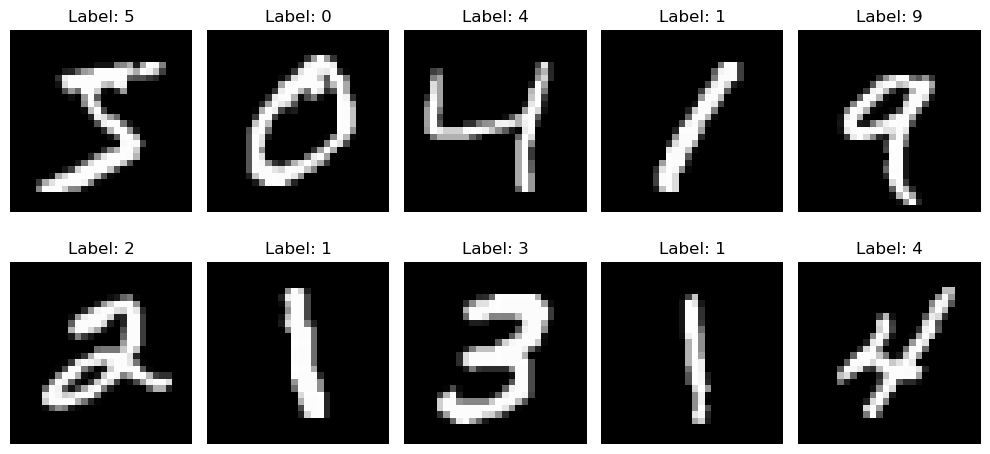

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training data normalized:", X_train.min(), X_train.max())
print("Testing data normalized:", X_test.min(), X_test.max())

Training data normalized: 0.0 1.0
Testing data normalized: 0.0 1.0


In [5]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.summary()

C:\Users\HEMA VARDHAN\New folder\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.9321 - loss: 0.2208 - val_accuracy: 0.9852 - val_loss: 0.0488
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 39s 16ms/step - accuracy: 0.9757 - loss: 0.0823 - val_accuracy: 0.9887 - val_loss: 0.0420
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9811 - loss: 0.0610 - val_accuracy: 0.9912 - val_loss: 0.0352
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.9854 - loss: 0.0490 - val_accuracy: 0.9898 - val_loss: 0.0390
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.9876 - loss: 0.0397 - val_accuracy: 0.9915 - val_loss: 0.0381
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9891 - loss: 0.0345 - val_accuracy: 0.9932 - val_loss: 0.0300
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9904 - loss: 0.0301 - val_accuracy: 0.9928 - val_loss: 0.0285
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 16ms/step - accuracy: 0.9915 -

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9920 - loss: 0.0277
Test Accuracy: 99.19999837875366 %
Test Loss: 0.02765463851392269


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step


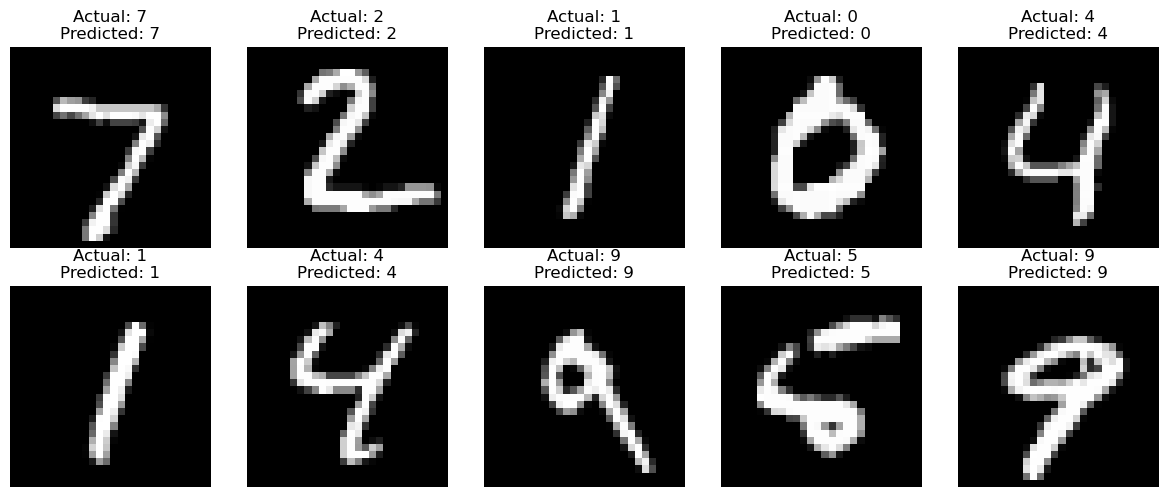

In [10]:
predictions = model.predict(X_test[:10])

plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_digit = np.argmax(predictions[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_digit}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
model.save("handwritten_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [12]:
from tensorflow.keras.models import load_model

loaded_model = load_model("handwritten_digit_model.keras")

print("Saved model loaded successfully!")

Saved model loaded successfully!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step


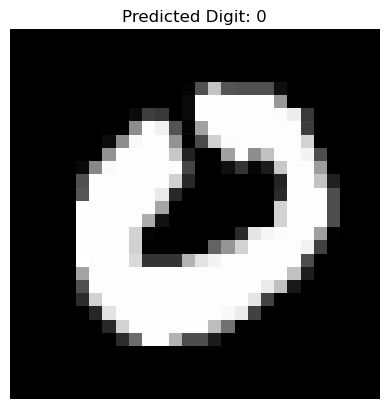

Actual Digit: 0
Predicted Digit: 0


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Select one test image
index = 25
image = X_test[index]

# Predict the digit using the saved model
prediction = loaded_model.predict(image.reshape(1, 28, 28, 1))
predicted_digit = np.argmax(prediction)

# Display the result
plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis("off")
plt.show()

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)